# 20. Initial-wave period review

Descriptive inspection of recorded illness-onset counts before fixing the first trajectory experiment. Same 585-region cohort as Notebook 19. Proposed initial history: March-April 2020 (61 calendar days). Proposed scoring origins: May 1-28, so all three target dates stay within May. A rolling 60-day weekly-refit protocol differs from a fixed March-April training fit. No model is trained here.

Later-selected features and previously examined data mean a 2020 replay would be exploratory. The source is cleaned onset counts, not all infections. Missing-onset records were excluded upstream.

Updated: blue curves show trailing 3-day means, including the current and previous two days. Only descriptive smoothing changed. Training/scoring dates, daily count targets and model features remain unchanged. The earlier 7-day output folder is retained for comparison.


In [4]:
"""Descriptive review before freezing the initial-wave forecasting protocol."""
from pathlib import Path
import json
import numpy as np
import pandas as pd

def review_initial_wave(repo,output):
    repo,output=Path(repo),Path(output);output.mkdir(parents=True,exist_ok=True)
    source=repo/'real_nj_cleaning_outputs'/'Real NJ COVID Zip.csv'
    data=pd.read_csv(source,usecols=['zip','date','onset_record_count'],dtype={'zip':str},parse_dates=['date']).rename(columns={'onset_record_count':'cases_today'})
    assert not data.duplicated(['zip','date']).any()
    ids=pd.read_csv(repo/'required_pressure_selection_outputs'/'required_pressure_20261026T183725469346Z'/'common_regions.csv',dtype=str)['zip']
    frame=data.loc[data.zip.isin(ids)&data.date.between('2020-02-01','2020-06-30')].copy()
    assert frame.zip.nunique()==585
    daily=frame.groupby('date').cases_today.sum().rename('recorded_onset_count').to_frame()
    daily['trailing_3d_mean']=daily.recorded_onset_count.rolling(3,min_periods=3).mean()
    daily.to_csv(output/'initial_wave_daily_counts.csv')
    monthly=frame.assign(month=frame.date.dt.to_period('M').astype(str)).groupby('month').agg(recorded_onset_count=('cases_today','sum'),region_days=('cases_today','size'),zero_region_days=('cases_today',lambda s:int(s.eq(0).sum())),regions=('zip','nunique'))
    monthly['zero_region_day_share']=monthly.zero_region_days/monthly.region_days
    monthly.to_csv(output/'monthly_onset_summary.csv')
    peak=daily.loc[daily.index>='2020-03-01','trailing_3d_mean'].idxmax()
    examples=['08901','07102','07030','08540']
    examples=[z for z in examples if z in set(ids)]
    region=frame.loc[frame.zip.isin(examples)].sort_values(['zip','date']).copy()
    region['trailing_3d_mean']=region.groupby('zip').cases_today.transform(lambda s:s.rolling(3,min_periods=3).mean())
    region.to_csv(output/'representative_zip_curves.csv',index=False)
    findings=dict(regions=585,review_start='2020-02-01',review_end='2020-06-30',aggregate_trailing_3d_peak_date=str(peak.date()),aggregate_trailing_3d_peak_count=float(daily.loc[peak,'trailing_3d_mean']),illustrative_training_period=['2020-03-01','2020-04-30'],training_calendar_days=61,illustrative_scoring_origins=['2020-05-01','2020-05-28'],reason_for_may28_end='All h=1/2/3 target dates remain within May.',examples_selected_before_plotting=examples,model_trained=False,final_window_selected=False)
    (output/'review_summary.json').write_text(json.dumps(findings,indent=2),encoding='utf-8')
    try:
        import matplotlib
        matplotlib.use('Agg')
        import matplotlib.pyplot as plt
        figures=output/'figures';figures.mkdir(exist_ok=True)
        fig,ax=plt.subplots(figsize=(13,5))
        ax.axvspan(pd.Timestamp('2020-03-01'),pd.Timestamp('2020-05-01'),color='#dbeafe',label='Proposed initial training period')
        ax.axvspan(pd.Timestamp('2020-05-01'),pd.Timestamp('2020-06-01'),color='#ccfbf1',label='Proposed scoring month')
        ax.plot(daily.index,daily.recorded_onset_count,color='#94a3b8',alpha=.6,label='Recorded onset count')
        ax.plot(daily.index,daily.trailing_3d_mean,color='#2563eb',lw=2,label='Trailing 3-day mean')
        ax.axvline(peak,color='#475569',ls=':',label=f'3-day mean peak: {peak:%Y-%m-%d}')
        ax.set(title='Initial COVID wave: recorded onset counts in 585 NJ regions',ylabel='Recorded onset cases',xlabel='Onset date')
        ax.legend(frameon=False,fontsize=9);ax.grid(alpha=.15)
        fig.text(.5,.01,'Retrospective onset-date data. Missing-onset records excluded. Shading is a proposed protocol, not a fitted model.',ha='center',fontsize=9)
        fig.tight_layout(rect=[0,.04,1,1]);fig.savefig(figures/'01_initial_wave_training_scoring.png',dpi=250);plt.close(fig)
        fig,axes=plt.subplots(2,2,figsize=(13,8))
        for ax,z in zip(axes.ravel(),examples):
            r=region.loc[region.zip.eq(z)]
            ax.axvspan(pd.Timestamp('2020-03-01'),pd.Timestamp('2020-05-01'),color='#dbeafe')
            ax.axvspan(pd.Timestamp('2020-05-01'),pd.Timestamp('2020-06-01'),color='#ccfbf1')
            ax.plot(r.date,r.cases_today,color='#94a3b8',alpha=.55,label='Daily count')
            ax.plot(r.date,r.trailing_3d_mean,color='#2563eb',label='Trailing 3-day mean')
            ax.set_title('NJ ZIP '+z);ax.tick_params(axis='x',rotation=25);ax.grid(alpha=.15);ax.legend(frameon=False,fontsize=8)
        fig.suptitle('Preselected ZIP examples: timing can vary across regions')
        fig.tight_layout();fig.savefig(figures/'02_preselected_zip_examples.png',dpi=250);plt.close(fig)
    except ImportError:
        print('Install matplotlib to create optional figures.')
    report='# Initial-wave period review\n\n'
    report+=f'The trailing three-day mean of recorded onset counts across the fixed 585-region cohort peaks on {peak:%Y-%m-%d}, at {daily.loc[peak,"trailing_3d_mean"]:.1f} cases per day. This is a descriptive peak of the available onset records, not a validated peak of all infections.\n\n'
    report+='Proposed first experiment: March-April 2020 initial history and May scoring. March 1-April 30 contains 61 calendar days, not exactly 60. A fixed March-April fit and a rolling 60-day weekly-refit experiment are different protocols. Under rolling refits, later May fits may incorporate earlier May labels after they mature. Exact fit dates and training origin boundaries depend on horizon and must be frozen before fitting. For scoring all three target dates within May, use May 1-28 forecast origins.\n\n'
    report+='This is retrospective descriptive inspection, not independent evaluation. Features were selected using 2021 data, so a 2020 replay with those features is not a fully prospective historical experiment. Missing illness-onset dates were excluded upstream; zero-filled dates represent no eligible observed onset record within the agreed source coverage. This review does not resolve onset missingness or reporting delays.\n\n'
    report+='## Before fitting\nConfirm fixed initial fit versus rolling retraining, the step size, cohort and predeclared trajectory metrics. Keep three predictions at one forecast origin together. Separate magnitude errors from slope/direction errors. No model was trained and no final window was selected by this notebook.\n'
    (output/'RESULTS.md').write_text(report,encoding='utf-8')
    print(json.dumps(findings,indent=2));print(monthly.to_string())
    return daily,monthly,findings


In [5]:
REPO = Path.cwd()
OUTPUT = REPO / 'initial_wave_review_outputs' / 'initial_wave_20261027_3day'
daily, monthly, findings = review_initial_wave(REPO, OUTPUT)
display(monthly)
print((OUTPUT / 'RESULTS.md').read_text(encoding='utf-8'))


{
  "regions": 585,
  "review_start": "2020-02-01",
  "review_end": "2020-06-30",
  "aggregate_trailing_3d_peak_date": "2020-04-01",
  "aggregate_trailing_3d_peak_count": 2610.6666666666665,
  "illustrative_training_period": [
    "2020-03-01",
    "2020-04-30"
  ],
  "training_calendar_days": 61,
  "illustrative_scoring_origins": [
    "2020-05-01",
    "2020-05-28"
  ],
  "reason_for_may28_end": "All h=1/2/3 target dates remain within May.",
  "examples_selected_before_plotting": [
    "08901",
    "07102",
    "07030",
    "08540"
  ],
  "model_trained": false,
  "final_window_selected": false
}
         recorded_onset_count  region_days  zero_region_days  regions  zero_region_day_share
month                                                                                       
2020-02                    52        16965             16913      585               0.996935
2020-03                 33319        18135             10209      585               0.562945
2020-04               

,recorded_onset_count,region_days,zero_region_days,regions,zero_region_day_share
month,,,,,
2020-02,52,16965,16913,585,0.996935
2020-03,33319,18135,10209,585,0.562945
2020-04,46959,17550,7385,585,0.420798
2020-05,10742,18135,13016,585,0.717728
2020-06,4956,17550,14279,585,0.813618


# Initial-wave period review

The trailing three-day mean of recorded onset counts across the fixed 585-region cohort peaks on 2020-04-01, at 2610.7 cases per day. This is a descriptive peak of the available onset records, not a validated peak of all infections.

Proposed first experiment: March-April 2020 initial history and May scoring. March 1-April 30 contains 61 calendar days, not exactly 60. A fixed March-April fit and a rolling 60-day weekly-refit experiment are different protocols. Under rolling refits, later May fits may incorporate earlier May labels after they mature. Exact fit dates and training origin boundaries depend on horizon and must be frozen before fitting. For scoring all three target dates within May, use May 1-28 forecast origins.

This is retrospective descriptive inspection, not independent evaluation. Features were selected using 2021 data, so a 2020 replay with those features is not a fully prospective historical experiment. Missing illness-onset dates were e

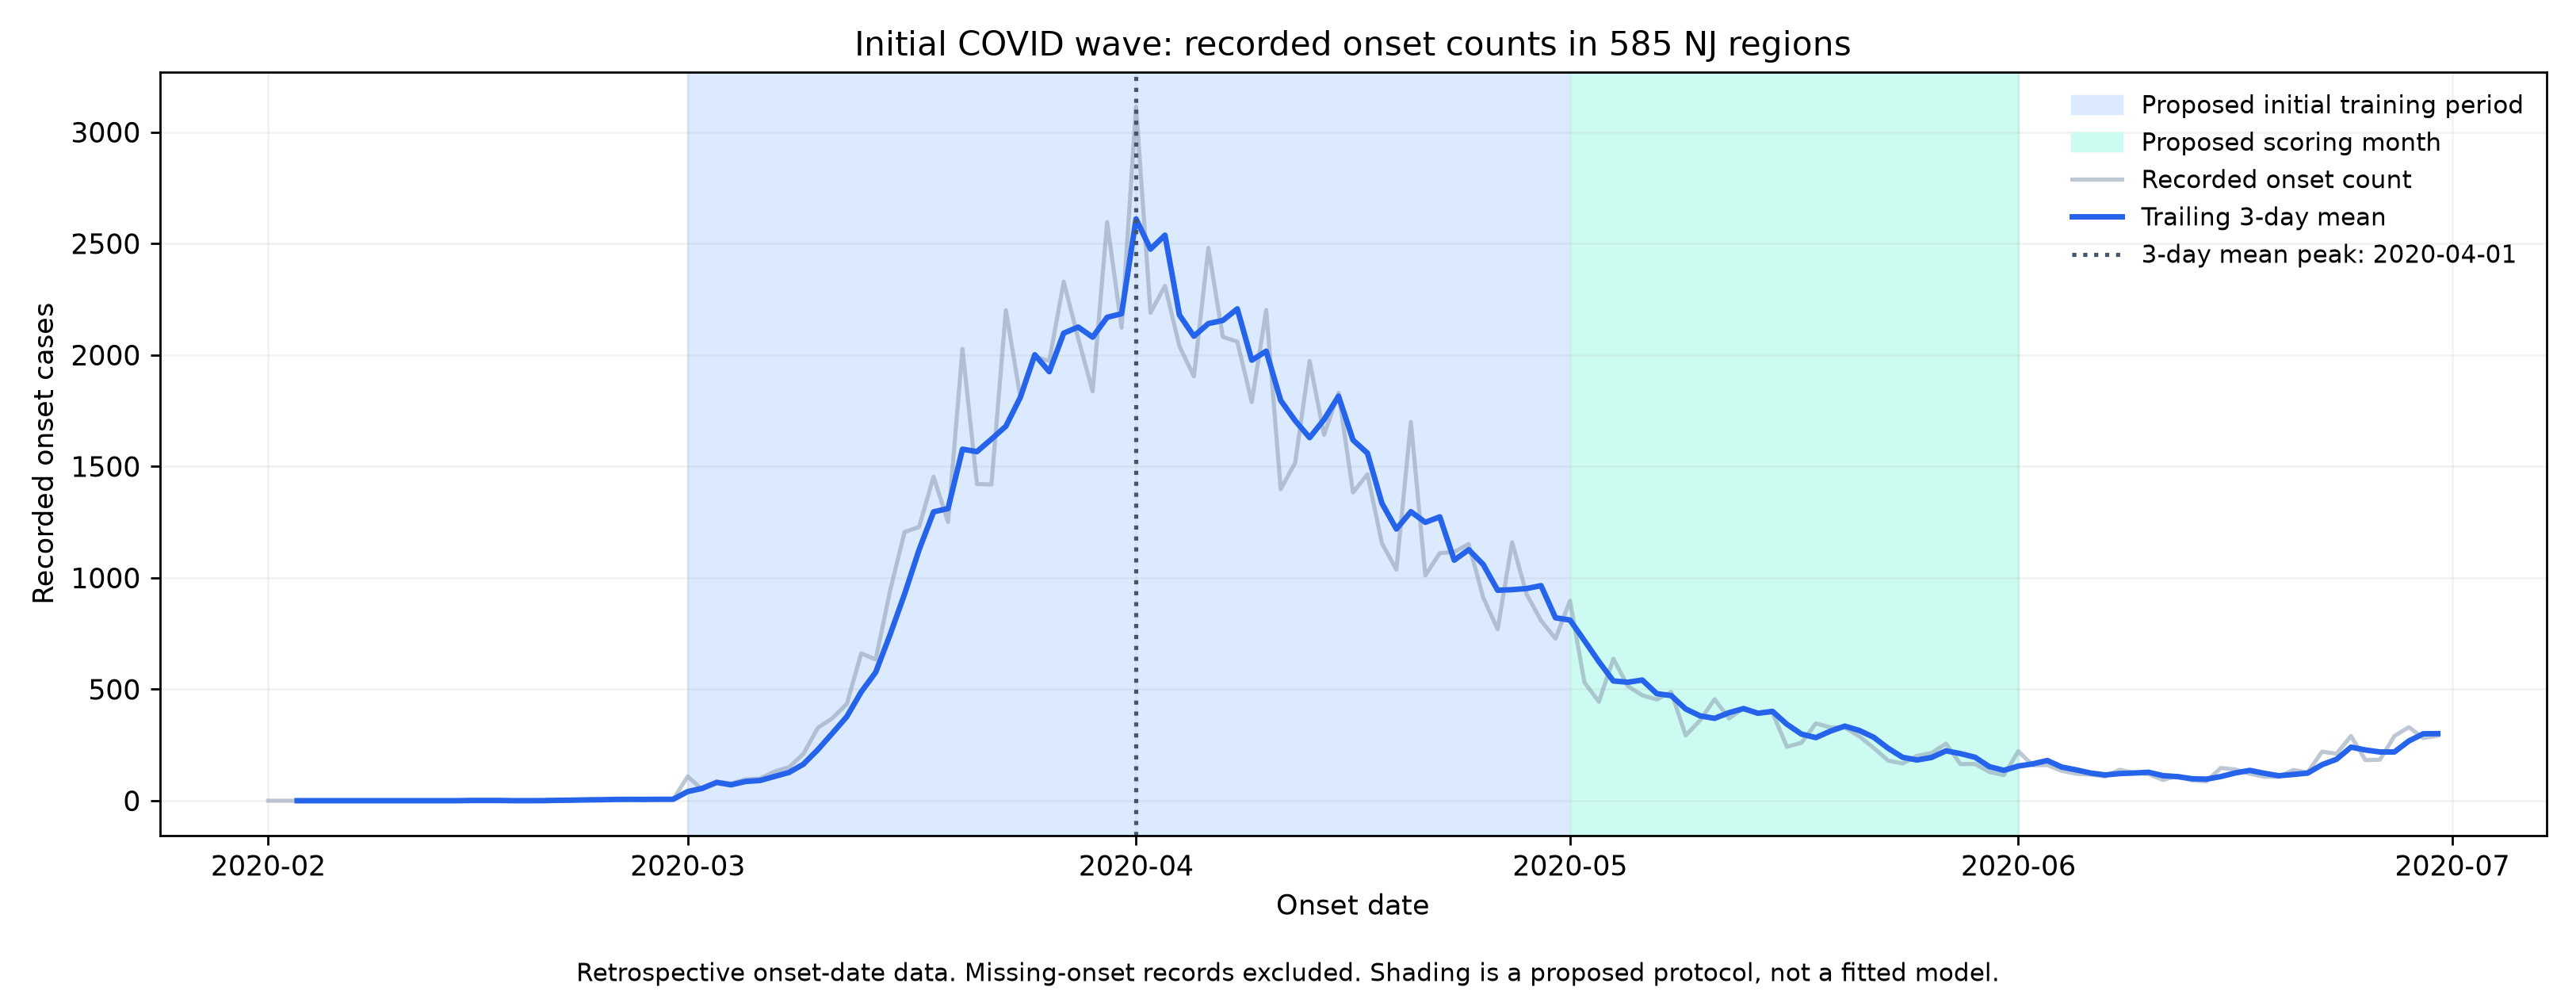

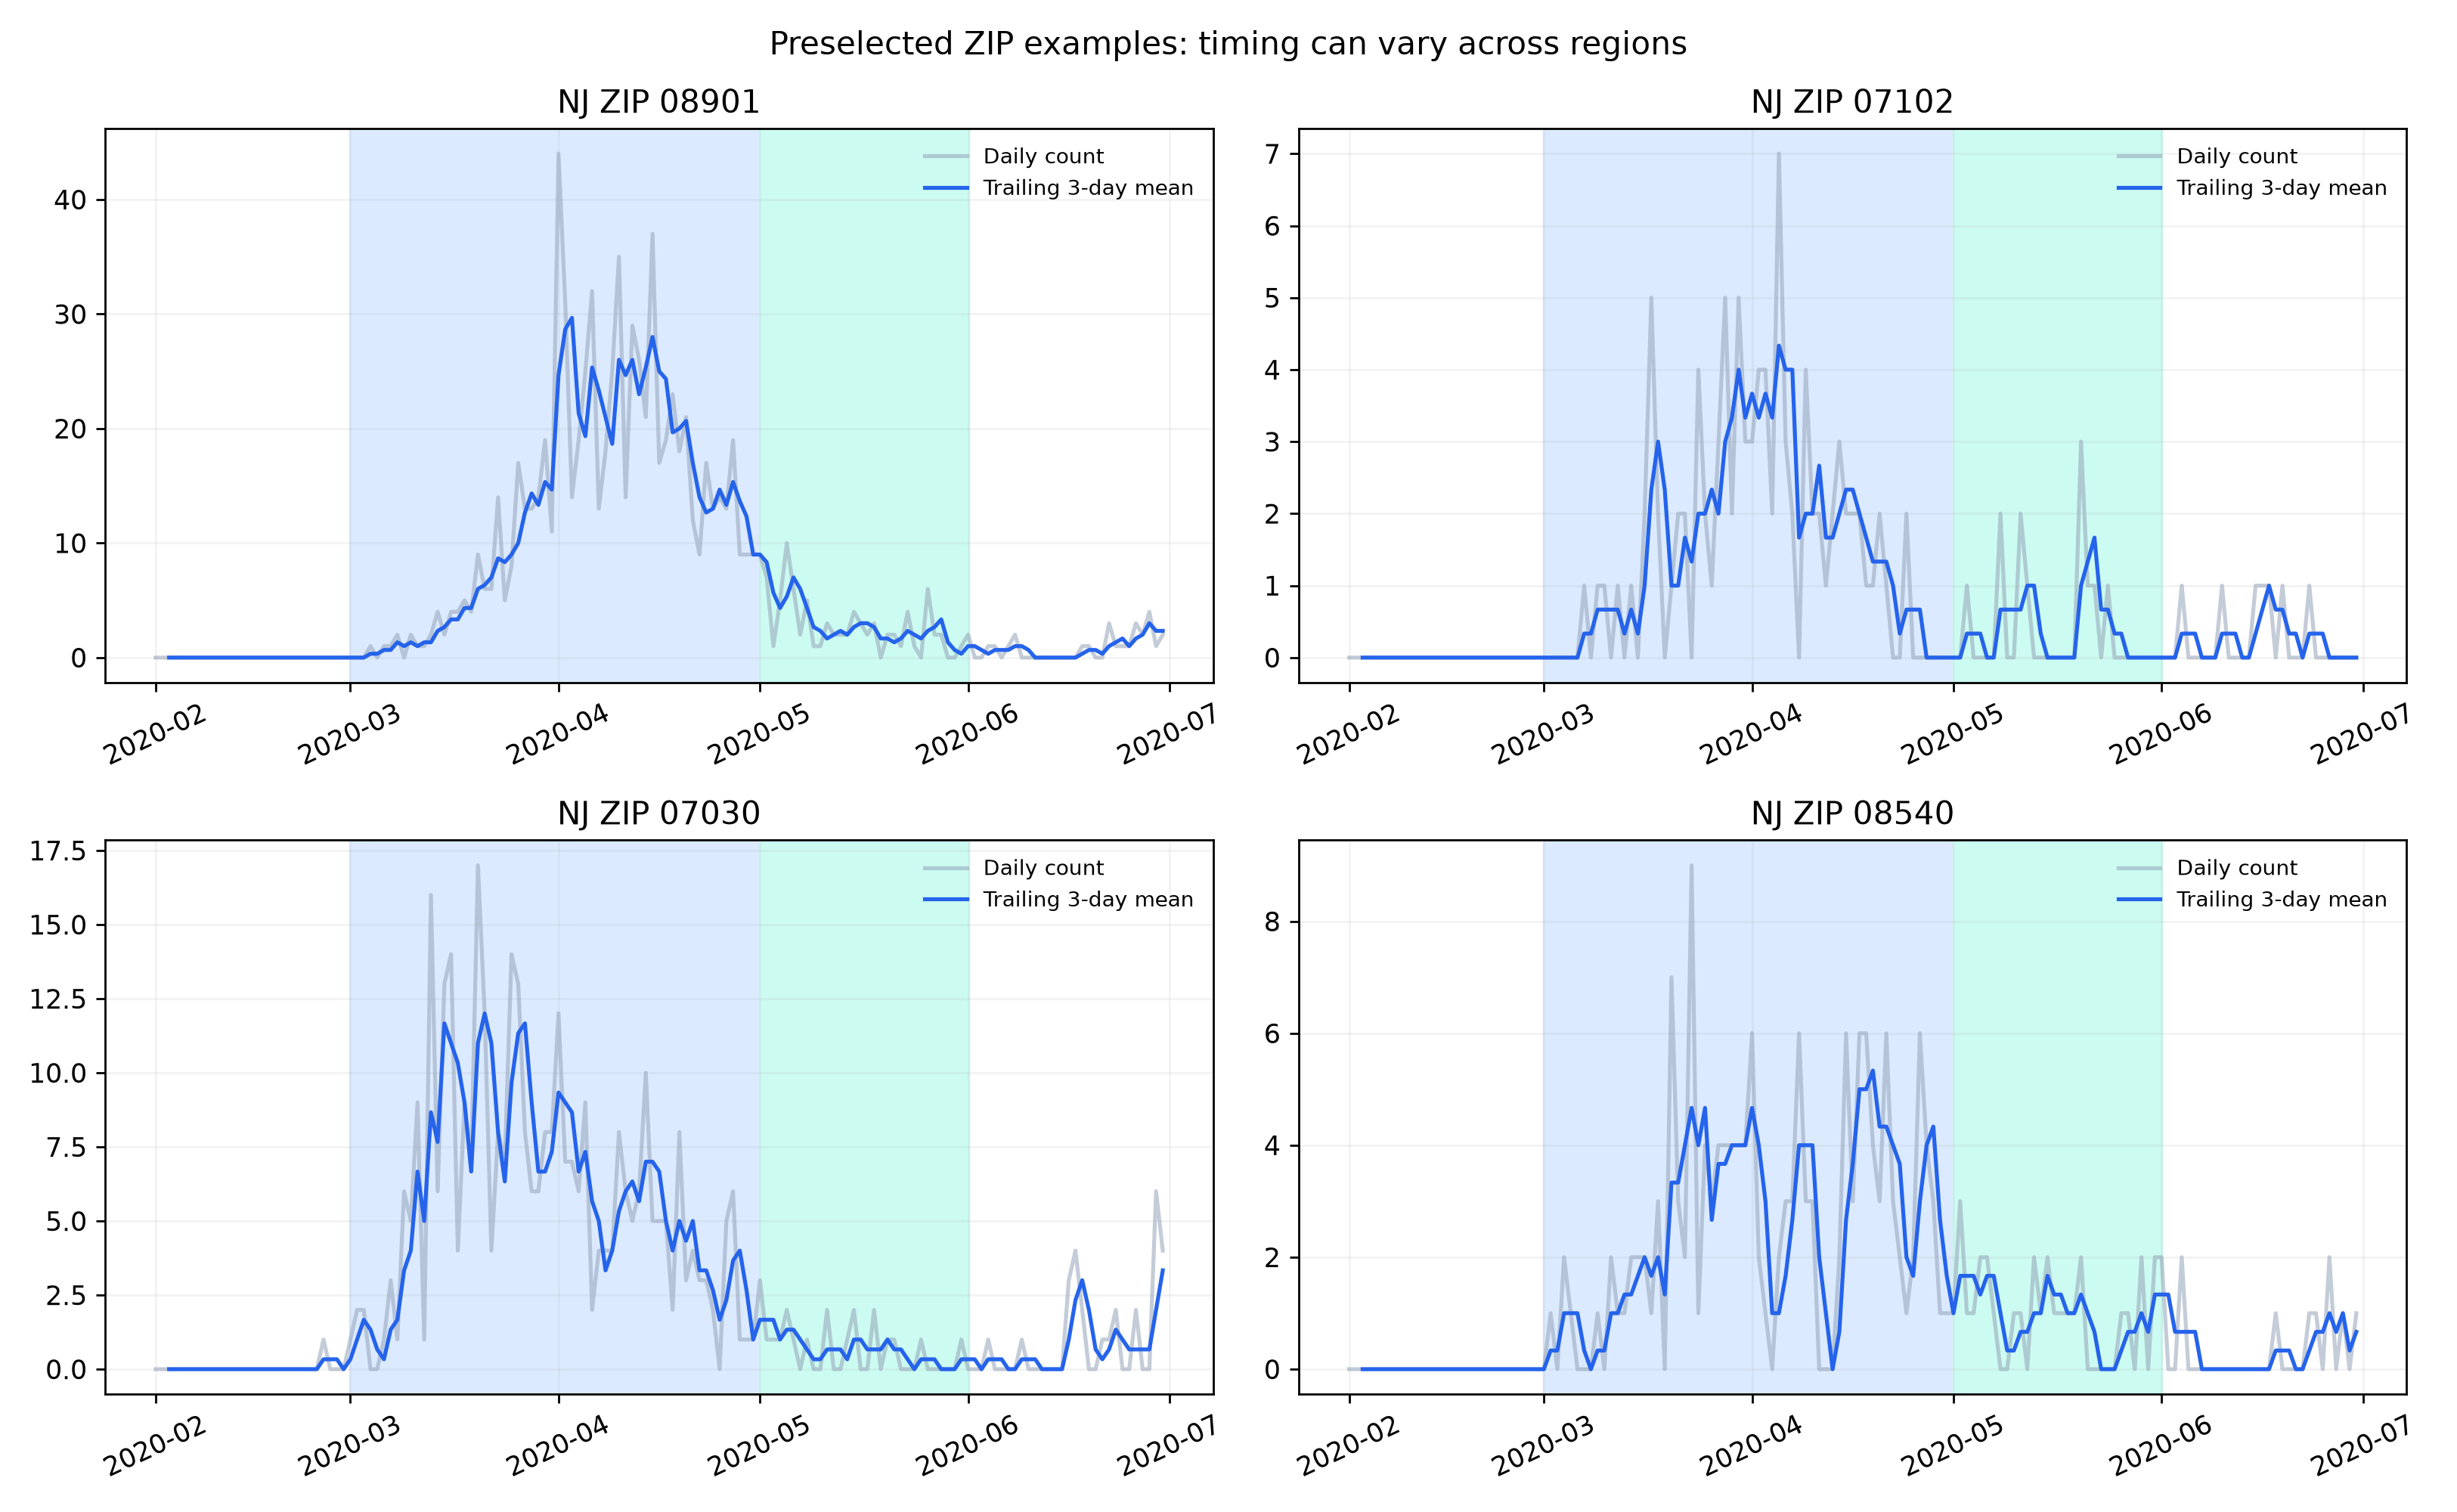

In [6]:
from IPython.display import Image, display
for name in ['01_initial_wave_training_scoring.png', '02_preselected_zip_examples.png']:
    image_path = OUTPUT / 'figures' / name
    if image_path.exists():
        display(Image(filename=str(image_path)))
